# ПР-13. Многослойный персептрон на табличных данных

Данные `o_churn_synthetic.csv`, те же, что в ПР-8 и ПР-9 (в ПР-8 на них обучены бустинг и случайный лес, иначе сравнение невозможно): 3000 абонентов, целевой признак `churn` (1 = ушёл). **Датасет синтетический, это не данные реального оператора.**

Разбиение то же, что в ПР-8: 80/20 со стратификацией и `random_state=42`. Метрика как в ПР-7–ПР-9: ROC-AUC.

Вариант B: подобрать архитектуру MLP, применить раннюю остановку и сравнить сеть с XGBoost из ПР-8 по качеству, времени обучения и стабильности при разных `random_state`.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost
from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

DATA_PATH = "../data/o_churn_synthetic.csv"
SEED = 42
CAT = ["region", "tariff"]

df = pd.read_csv(DATA_PATH)
X = df.drop(columns=["churn", "subscriber_code"])
y = df["churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)


def make_prep(scale=True):
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CAT)],
                             remainder=StandardScaler() if scale else "passthrough")


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print("train:", X_train.shape, "test:", X_test.shape)
print("scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__)

train: (2400, 11) test: (600, 11)
scikit-learn 1.9.1 | xgboost 3.4.1


## Веха 13.1. Подбор архитектуры

Пайплайн: one-hot для категорий, `StandardScaler` для числовых признаков, `MLPClassifier`. У всех вариантов одинаковые настройки обучения: оптимизатор Adam, `learning_rate_init=0.001`, L2-регуляризация `alpha=0.001`, ранняя остановка (`early_stopping=True`: 15% train откладывается для валидации, обучение прекращается, если 20 эпох подряд нет улучшения). Перебираю 9 архитектур: один, два и три скрытых слоя разной ширины. Оценка: 5-кратная стратифицированная кросс-валидация на train.

In [2]:
ARCHS = [(8,), (16,), (32,), (64,), (16, 8), (32, 16), (64, 32), (128, 64), (64, 32, 16)]


def mlp(hidden, seed=SEED, early=True, alpha=1e-3):
    return make_pipeline(make_prep(), MLPClassifier(
        hidden_layer_sizes=hidden, alpha=alpha, learning_rate_init=1e-3, max_iter=1000,
        early_stopping=early, validation_fraction=0.15, n_iter_no_change=20,
        random_state=seed))


rows = []
for h in ARCHS:
    s = cross_val_score(mlp(h), X_train, y_train, cv=cv, scoring="roc_auc")
    params = sum(a * b + b for a, b in zip((26,) + h, h + (1,)))   # 26 входов после one-hot
    rows.append({"архитектура": str(h), "весов": params, "ROC-AUC CV": s.mean(), "std": s.std()})
arch = pd.DataFrame(rows).set_index("архитектура")
arch.round(4)

,весов,ROC-AUC CV,std
архитектура,,,
"(8,)",225,0.7657,0.0155
"(16,)",449,0.7647,0.0152
"(32,)",897,0.7683,0.0204
"(64,)",1793,0.7668,0.0168
"(16, 8)",577,0.7675,0.0088
"(32, 16)",1409,0.7663,0.0153
"(64, 32)",3841,0.7697,0.0156
"(128, 64)",11777,0.7601,0.0159
"(64, 32, 16)",4353,0.7623,0.0135


**Что видно.** Все архитектуры дают почти одно и то же: ROC-AUC от 0,760 до 0,770, а разброс по фолдам у каждой 0,009–0,020. Разница между лучшей (64, 32) и самой маленькой (8,) всего 0,004, в несколько раз меньше этого разброса. Сеть с 225 весами работает не хуже сети с 3841. Самые большие сети, (128, 64) с 11 777 весами и трёхслойная (64, 32, 16), чуть хуже: на 2400 абонентах лишние веса только помогают переобучаться.

Формально лучшая (64, 32), беру её, но выбор архитектуры здесь почти ничего не решает.

## Веха 13.2. Ранняя остановка и кривая потерь

лучшая архитектура: (64, 32)
ранняя остановка: обучение остановлено на эпохе 27 | лучшая точность на валидации на эпохе 6


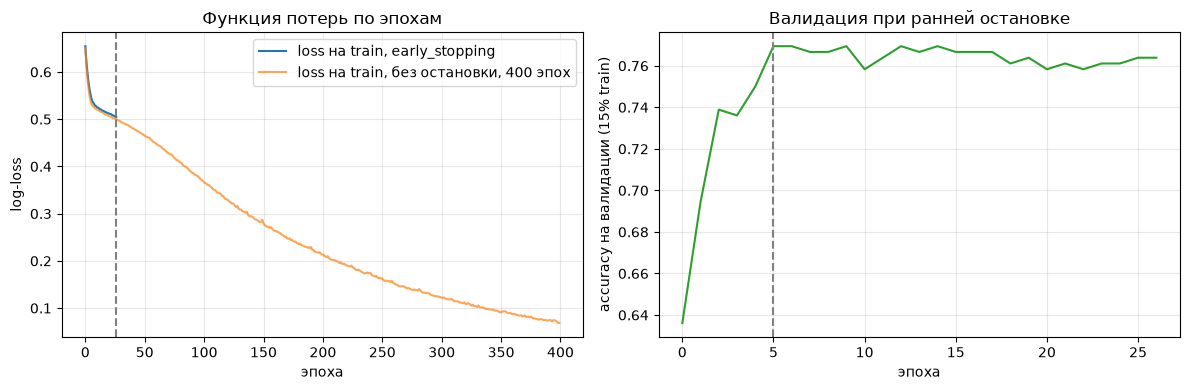

с ранней остановкой: ROC-AUC train 0.782, test 0.795
без остановки, 400 эпох: ROC-AUC train 0.999, test 0.683


In [3]:
BEST = tuple(int(x) for x in arch["ROC-AUC CV"].idxmax().strip("(),").split(",") if x.strip())
best_pipe = mlp(BEST).fit(X_train, y_train)
net = best_pipe[-1]
print("лучшая архитектура:", BEST)
print("ранняя остановка: обучение остановлено на эпохе", net.n_iter_,
      "| лучшая точность на валидации на эпохе", int(np.argmax(net.validation_scores_)) + 1)

with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    no_es = mlp(BEST, early=False, alpha=1e-5)
    no_es.set_params(mlpclassifier__max_iter=400).fit(X_train, y_train)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(net.loss_curve_, label="loss на train, early_stopping")
axes[0].plot(no_es[-1].loss_curve_, label="loss на train, без остановки, 400 эпох", alpha=0.7)
axes[0].axvline(net.n_iter_ - 1, ls="--", color="gray")
axes[0].set(xlabel="эпоха", ylabel="log-loss", title="Функция потерь по эпохам")
axes[0].legend()
axes[1].plot(net.validation_scores_, color="C2")
axes[1].axvline(int(np.argmax(net.validation_scores_)), ls="--", color="gray")
axes[1].set(xlabel="эпоха", ylabel="accuracy на валидации (15% train)", title="Валидация при ранней остановке")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
for name, p in [("с ранней остановкой", best_pipe), ("без остановки, 400 эпох", no_es)]:
    print(f"{name}: ROC-AUC train {roc_auc_score(y_train, p.predict_proba(X_train)[:, 1]):.3f},"
          f" test {roc_auc_score(y_test, p.predict_proba(X_test)[:, 1]):.3f}")

**На какой эпохе остановилось обучение.** На эпохе **27**. Лучшая доля верных ответов на валидационной части была на эпохе 6, после неё 20 эпох подряд улучшения не было, и обучение прекратилось (`n_iter_no_change=20`). После остановки scikit-learn возвращает сети веса с лучшей по валидации эпохи (6-й), а не с последней.

**Что показывает кривая потерь.**

- С ранней остановкой loss на train упал до 0,50 и остановился. ROC-AUC на train 0,782, на test 0,795: сеть не переобучилась.
- Без остановки за 400 эпох loss на train продолжает падать, до 0,07: сеть запоминает обучающих абонентов. ROC-AUC на train 0,999, а на test **0,683**, на 0,11 хуже. Если смотреть только на падающую кривую loss, кажется, что сеть всё лучше учится, а на самом деле она всё сильнее переобучается.

Поэтому число эпох нельзя выбирать произвольно: нужна валидация или ранняя остановка.

In [4]:
stops = [mlp(BEST, seed=s).fit(X_train, y_train)[-1].n_iter_ for s in range(10)]
print("эпоха остановки при 10 разных random_state:", stops)

эпоха остановки при 10 разных random_state: [36, 28, 30, 53, 33, 45, 41, 27, 33, 31]


При разных `random_state` (разные начальные веса и разное деление на обучение и валидацию внутри train) остановка происходит на эпохе от 27 до 53. Количество эпох это не свойство данных: его определяет ранняя остановка в каждом запуске.

## Веха 13.3. Зачем масштабировать признаки

Та же сеть (64, 32) с масштабированием и без, с ранней остановкой и без неё (300 эпох):

In [5]:
rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    for scale in [True, False]:
        for early in [True, False]:
            pipe = make_pipeline(make_prep(scale), MLPClassifier(
                hidden_layer_sizes=BEST, alpha=1e-3, max_iter=1000 if early else 300,
                early_stopping=early, validation_fraction=0.15, n_iter_no_change=20, random_state=SEED))
            s = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
            n = pipe.fit(X_train, y_train)[-1]
            rows.append({"масштабирование": "да" if scale else "нет",
                         "ранняя остановка": "да" if early else "нет (300 эпох)",
                         "ROC-AUC CV": s.mean(), "std": s.std(), "худший фолд": s.min(),
                         "эпох": n.n_iter_, "loss на train": n.loss_})
pd.DataFrame(rows).set_index(["масштабирование", "ранняя остановка"]).round(4)

ROC-AUC CV     std  худший фолд  эпох  \
масштабирование ранняя остановка                                          
да              да                    0.7697  0.0156       0.7525    27   
                нет (300 эпох)        0.6799  0.0316       0.6356   300   
нет             да                    0.7218  0.0794       0.5659    65   
                нет (300 эпох)        0.7558  0.0108       0.7427   252   

                                  loss на train  
масштабирование ранняя остановка                 
да              да                       0.5046  
                нет (300 эпох)           0.1284  
нет             да                       0.5917  
                нет (300 эпох)           0.5034

**Вывод.**

- Лучший и самый стабильный вариант: **масштабирование + ранняя остановка** (0,770 ± 0,016).
- **Без масштабирования** сеть с ранней остановкой работает плохо и нестабильно: в среднем 0,722, а разброс по фолдам 0,079, в 5 раз больше. В худшем фолде ROC-AUC около 0,57, почти как у случайного угадывания. `monthly_charge_som` (сотни сомов) и `balance_som` дают на входе нейронов значения в сотни раз больше, чем `autopay` (0 или 1): градиенты по этим весам огромные, по остальным крошечные, и Adam с одной скоростью обучения не может нормально двигаться по всем направлениям. Ранняя остановка срабатывает раньше, чем сеть чему-то научилась.
- Без масштабирования и без остановки получается 0,756, но не потому, что это хорошо: сеть за 300 эпох просто медленно доучивается (loss 0,50), и неполное обучение случайно работает как регуляризация.
- С масштабированием, но без остановки сеть за 300 эпох переобучается (loss 0,13, ROC-AUC 0,680).

То есть масштабирование нужно, чтобы сеть вообще нормально обучалась, а ранняя остановка, чтобы она не переобучилась.

## Веха 13.4. Сравнение с градиентным бустингом из ПР-8

Модели на одном и том же train и test:

- **MLP (64, 32)** с ранней остановкой;
- **XGBoost из ПР-8** с подобранными там параметрами: 127 деревьев, `learning_rate=0.05`, `max_depth=3`;
- тот же XGBoost с `subsample=0.8`: без него XGBoost полностью детерминирован, и `random_state` ни на что не влияет, а с ним каждое дерево обучается на случайных 80% строк, как и у MLP есть случайность;
- логистическая регрессия, лучшая модель ПР-8, для ориентира.

Каждую модель обучаю 10 раз с `random_state` от 0 до 9. Время обучения это медиана 10 запусков.

In [6]:
def report(name, make, seeds=range(10)):
    aucs, f1s, secs = [], [], []
    for s in seeds:
        pipe = make(s)
        t0 = time.perf_counter()
        pipe.fit(X_train, y_train)
        secs.append(time.perf_counter() - t0)
        proba = pipe.predict_proba(X_test)[:, 1]
        aucs.append(roc_auc_score(y_test, proba))
        f1s.append(f1_score(y_test, proba >= 0.5))
    cvs = cross_val_score(make(SEED), X_train, y_train, cv=cv, scoring="roc_auc")
    return {"Модель": name, "ROC-AUC CV": cvs.mean(), "ROC-AUC test (среднее по 10 seed)": np.mean(aucs),
            "std по seed": np.std(aucs), "мин": np.min(aucs), "макс": np.max(aucs),
            "F1 test": np.mean(f1s), "обучение, с": np.median(secs)}


rows = [
    report(f"MLP {BEST}, early_stopping", lambda s: mlp(BEST, seed=s)),
    report("XGBoost из ПР-8 (127 деревьев, 0.05, depth 3)", lambda s: make_pipeline(make_prep(False), XGBClassifier(
        n_estimators=127, learning_rate=0.05, max_depth=3, random_state=s, n_jobs=1))),
    report("XGBoost из ПР-8, subsample=0.8", lambda s: make_pipeline(make_prep(False), XGBClassifier(
        n_estimators=127, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=s, n_jobs=1))),
    report("Логрегрессия (ПР-8)", lambda s: make_pipeline(make_prep(), LogisticRegression(max_iter=1000))),
]
comparison = pd.DataFrame(rows).set_index("Модель")
comparison.round(4)

,ROC-AUC CV,ROC-AUC test (среднее по 10 seed),std по seed,мин,макс,F1 test,"обучение, с"
Модель,,,,,,,
"MLP (64, 32), early_stopping",0.7697,0.7954,0.0031,0.7914,0.8025,0.6075,0.0908
"XGBoost из ПР-8 (127 деревьев, 0.05, depth 3)",0.7723,0.7924,0.0000,0.7924,0.7924,0.5858,0.0182
"XGBoost из ПР-8, subsample=0.8",0.7709,0.7981,0.0025,0.7941,0.8028,0.5923,0.0192
Логрегрессия (ПР-8),0.7776,0.8062,0.0000,0.8062,0.8062,0.6111,0.0041


## Итог

| Модель | ROC-AUC CV | ROC-AUC test, среднее по 10 seed | std по seed | F1 test | Обучение |
| --- | --- | --- | --- | --- | --- |
| MLP (64, 32), early_stopping | 0,770 | 0,795 | 0,003 | 0,608 | около 0,09 с |
| XGBoost из ПР-8 | 0,772 | 0,792 | 0 (детерминирован) | 0,586 | около 0,02 с |
| XGBoost из ПР-8, `subsample=0.8` | 0,771 | 0,798 | 0,003 | 0,592 | около 0,02 с |
| Логистическая регрессия (ПР-8) | **0,778** | **0,806** | 0 | **0,611** | около 0,004 с |

- **Качество.** MLP и XGBoost на одном уровне: на кросс-валидации 0,770 против 0,772, на test 0,795 против 0,792–0,798. Разница меньше разброса между фолдами (около 0,015) и между seed. Ни одна из двух моделей не лучше логистической регрессии.
- **Время.** MLP обучается в 4–5 раз дольше XGBoost (0,09 с против 0,02 с) и в 20–25 раз дольше логистической регрессии. При 2400 строках это доли секунды, но на больших данных разница станет заметной; к тому же для MLP пришлось перебирать архитектуры и следить за эпохами.
- **Стабильность.** При разных `random_state` ROC-AUC MLP на test менялся от 0,791 до 0,802 (std 0,003), так же, как у XGBoost со `subsample` (0,794–0,803). Ранняя остановка делает сеть устойчивой. Без масштабирования или без ранней остановки (веха 13.3) сеть была бы гораздо менее стабильной.
- Эти данные близки к линейно разделимым (логистическая регрессия лучше всех, а у SVM в ПР-9 лучшим оказалось почти линейное ядро), поэтому ни бустинг, ни сеть не могут найти сложных зависимостей, которых в данных нет.

**Вывод: нейронная сеть на этих табличных данных не оправдана.** По качеству она равна бустингу из ПР-8 и уступает логистической регрессии, обучается дольше, требует масштабирования, подбора архитектуры и ранней остановки и хуже объясняется (у бустинга есть важность признаков, у логистической регрессии коэффициенты). Это совпадает с подсказкой из задания: на табличных данных умеренного объёма градиентный бустинг обычно не хуже MLP. Здесь они вровень, но выигрыша от сети нет. Для этой задачи я бы выбрал логистическую регрессию.